# Evidencia 3 — Morfosintaxis: categorías gramaticales y lematización

**SONORA · PLN · E3-01 a E3-04 · corpus completo `lyrics_full_v1`.**

Se reutiliza la anotación de las 3 155 772 letras canónicas, no sólo la demo FMA.
spaCy 3.8.18, `en_core_web_sm` 3.8.0, sin NER; vista `lyrics_analysis`.
Los saltos de verso fuerzan fronteras; el parser puede subdividir un verso.
Se preserva la superficie original; formas g-dropping admitidas se analizan mediante
texto sombra de igual longitud (`runnin'` → `running`) conservando índices.
No se corrigen las predicciones después de observarlas.

Las métricas son descriptivas sobre **todos los splits**. No se entrenan modelos,
no se eligen hiperparámetros y no se evalúa recuperación con test.
`frequency/word_pos.parquet` agrega `(split, lower, lemma, upos)`;
`group_pos.parquet` agrega `(split, tag, decade, upos)` sobre la misma anotación.
`doc_stats/` aporta los tamaños documentales. Los tags son etiquetas de la fuente,
no géneros validados; `year` tampoco certifica fecha de composición.

**Denominadores:** todos los tokens spaCy no espaciales; alternativamente todos salvo
UPOS `PUNCT`, `SYM`, `SPACE`. Esta segunda política conserva números, clíticos y `X`:
no equivale a palabras alfabéticas ni al tokenizador regex de E2. No se retiran
stopwords ni vocablos. Las proporciones ponderan tokens: las letras largas y estribillos
repetidos pesan más. No representan la letra media ni causalidad entre género y gramática.

In [1]:
import json, sys
from pathlib import Path
from collections import Counter
import numpy as np
import pyarrow as pa, pyarrow.compute as pc, pyarrow.dataset as ds, pyarrow.parquet as pq
import matplotlib.pyplot as plt
import yaml
from IPython.display import display, Markdown
ROOT = Path.cwd()
sys.path.insert(0, str(ROOT/'packages/sonora/src'))
from sonora import viz
from sonora.nlp.morphology import distributions, lemma_summary, EXCLUDED
from sonora.nlp.frequency import decade_of
viz.apply_style()
NLP = ROOT/'data/processed/nlp/lyrics_full_v1'
FIG = ROOT/'reports/figures/E3'
manifest = json.loads((ROOT/'manifests/nlp/lyrics_full_v1.json').read_text(encoding='utf-8'))
annotation = manifest['annotations']['spacy_sm_v1']
assert annotation['status'] == 'complete' and annotation['tasks_remaining'] == 0
words = pq.read_table(NLP/'frequency/word_pos.parquet')
groups = pq.read_table(NLP/'frequency/group_pos.parquet').to_pylist()
docs = ds.dataset(NLP/'doc_stats').to_table(columns=['lyrics_id','tag','year'])
assert docs.num_rows == 3155772
def show(rows):
    if not rows: return
    cols = list(rows[0])
    def val(x):
        if x is None: return '—'
        if isinstance(x, float): return f'{x:.3f}'
        return str(x).replace('|', r'\|').replace('\n', ' / ')
    display(Markdown('\n'.join(['| '+' | '.join(cols)+' |', '|'+'---|'*len(cols)] +
                              ['| '+' | '.join(val(r[c]) for c in cols)+' |' for r in rows])))
global_pos = distributions(groups)
N = sum(r['count'] for r in global_pos)
assert N == int(pc.sum(words['count']).as_py()) == 1033733693
print('Configuración:', annotation['config'])
print('Letras:', docs.num_rows, '| tokens:', N)

Configuración: {'annotation_version': 'spacy-lines-gdrop-v1', 'model': 'en_core_web_sm', 'model_version': '3.8.0', 'spacy': '3.8.18', 'sentence_policy': 'line_break_forced_boundary_plus_parser', 'text_view': 'lyrics_analysis', 'docs_per_task': 500, 'corpus_run_id': 'lyrics_full_v1', 'gdrop_forms_sha256': '8d9d55bd487582412f1f29136590fee06d10ebc0915acfea0991c1212864da1e'}
Letras: 3155772 | tokens: 1033733693


## 1. Distribución gramatical completa (E3-02)

Las dos columnas porcentuales usan universos distintos, declarados en cada fila.
Los excluidos se conservan en la tabla y carecen de porcentaje en el segundo universo.

| group | upos | count | total | nonpunct_total | pct_all | pct_nonpunct |
|---|---|---|---|---|---|---|
| all | PRON | 185818230 | 1033733693 | 954321127 | 17.975 | 19.471 |
| all | VERB | 159154194 | 1033733693 | 954321127 | 15.396 | 16.677 |
| all | NOUN | 146979569 | 1033733693 | 954321127 | 14.218 | 15.401 |
| all | PUNCT | 79196665 | 1033733693 | 954321127 | 7.661 | — |
| all | ADP | 78510983 | 1033733693 | 954321127 | 7.595 | 8.227 |
| all | AUX | 75380981 | 1033733693 | 954321127 | 7.292 | 7.899 |
| all | DET | 66877498 | 1033733693 | 954321127 | 6.470 | 7.008 |
| all | ADV | 49459463 | 1033733693 | 954321127 | 4.785 | 5.183 |
| all | ADJ | 46440536 | 1033733693 | 954321127 | 4.493 | 4.866 |
| all | PROPN | 44732914 | 1033733693 | 954321127 | 4.327 | 4.687 |
| all | PART | 33419929 | 1033733693 | 954321127 | 3.233 | 3.502 |
| all | CCONJ | 24602151 | 1033733693 | 954321127 | 2.380 | 2.578 |
| all | SCONJ | 22359077 | 1033733693 | 954321127 | 2.163 | 2.343 |
| all | INTJ | 13809402 | 1033733693 | 954321127 | 1.336 | 1.447 |
| all | NUM | 6233893 | 1033733693 | 954321127 | 0.603 | 0.653 |
| all | X | 542307 | 1033733693 | 954321127 | 0.052 | 0.057 |
| all | SYM | 215901 | 1033733693 | 954321127 | 0.021 | — |

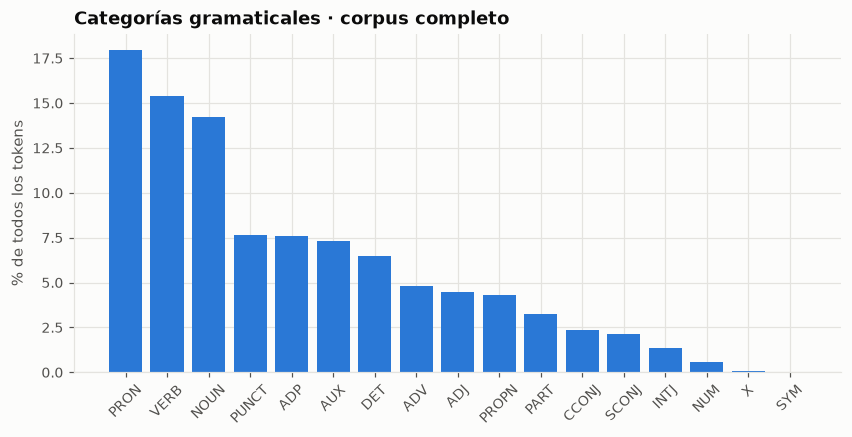

In [2]:
show(global_pos)
assert abs(sum(r['pct_all'] for r in global_pos)-100) < 1e-8
assert abs(sum(r['pct_nonpunct'] or 0 for r in global_pos)-100) < 1e-8
fig, ax = plt.subplots(figsize=(9,4))
ax.bar([r['upos'] for r in global_pos], [r['pct_all'] for r in global_pos], color=viz.SEQUENTIAL)
ax.set(ylabel='% de todos los tokens', title='Categorías gramaticales · corpus completo')
ax.tick_params(axis='x', rotation=45)
viz.save(fig, FIG/'pos_global.png'); plt.show()

## 2. Comparaciones por tag y década (E3-03)

Conteos documentales completos y porcentajes por token sin `PUNCT/SYM/SPACE`.
Década = `year // 10 * 10` sólo entre 1900 y 2022; los demás valores se agrupan
como desconocidos, sin imputación. Las décadas pequeñas se muestran en las tablas;
el gráfico temporal usa las de al menos 1 000 letras para reducir inestabilidad descriptiva.
No se interpreta una tendencia temporal como evolución de los mismos artistas:
cambian composición, cobertura y mezcla de tags del dataset.

tag


| grupo | letras | % letras | tokens | tokens sin puntuación/símbolos |
|---|---|---|---|---|
| country | 85258 | 2.702 | 21647642 | 20515588 |
| pop | 1336051 | 42.337 | 342698294 | 318439973 |
| rap | 959763 | 30.413 | 475239909 | 434918369 |
| rb | 153552 | 4.866 | 54322213 | 49340313 |
| rock | 621148 | 19.683 | 139825635 | 131106884 |

década


| grupo | letras | % letras | tokens | tokens sin puntuación/símbolos |
|---|---|---|---|---|
| 1900 | 100 | 0.003 | 20515 | 18659 |
| 1910 | 182 | 0.006 | 56944 | 51538 |
| 1920 | 1361 | 0.043 | 306188 | 277494 |
| 1930 | 1096 | 0.035 | 230963 | 208781 |
| 1940 | 1200 | 0.038 | 258130 | 235291 |
| 1950 | 9014 | 0.286 | 1740222 | 1600341 |
| 1960 | 39341 | 1.247 | 8274799 | 7594660 |
| 1970 | 62259 | 1.973 | 15201559 | 13956211 |
| 1980 | 93673 | 2.968 | 24648774 | 22677112 |
| 1990 | 213283 | 6.759 | 58599959 | 54067120 |
| 2000 | 435534 | 13.801 | 122625843 | 113490955 |
| 2010 | 1582505 | 50.146 | 544594794 | 503628374 |
| 2020 | 714159 | 22.630 | 256287771 | 235706796 |
| — | 2065 | 0.065 | 887232 | 807795 |

| group | upos | count | total | nonpunct_total | pct_all | pct_nonpunct |
|---|---|---|---|---|---|---|
| country | PRON | 3814602 | 21647642 | 20515588 | 17.621 | 18.594 |
| country | VERB | 3307727 | 21647642 | 20515588 | 15.280 | 16.123 |
| country | NOUN | 3098364 | 21647642 | 20515588 | 14.313 | 15.102 |
| country | ADP | 1746910 | 21647642 | 20515588 | 8.070 | 8.515 |
| country | AUX | 1705041 | 21647642 | 20515588 | 7.876 | 8.311 |
| country | DET | 1560483 | 21647642 | 20515588 | 7.209 | 7.606 |
| country | ADV | 1177952 | 21647642 | 20515588 | 5.441 | 5.742 |
| country | PUNCT | 1129945 | 21647642 | 20515588 | 5.220 | — |
| country | ADJ | 1048345 | 21647642 | 20515588 | 4.843 | 5.110 |
| country | PART | 744148 | 21647642 | 20515588 | 3.438 | 3.627 |
| country | PROPN | 702494 | 21647642 | 20515588 | 3.245 | 3.424 |
| country | CCONJ | 685390 | 21647642 | 20515588 | 3.166 | 3.341 |
| country | SCONJ | 530277 | 21647642 | 20515588 | 2.450 | 2.585 |
| country | INTJ | 250777 | 21647642 | 20515588 | 1.158 | 1.222 |
| country | NUM | 137393 | 21647642 | 20515588 | 0.635 | 0.670 |
| country | X | 5685 | 21647642 | 20515588 | 0.026 | 0.028 |
| country | SYM | 2109 | 21647642 | 20515588 | 0.010 | — |
| pop | PRON | 64317745 | 342698294 | 318439973 | 18.768 | 20.198 |
| pop | VERB | 53113499 | 342698294 | 318439973 | 15.499 | 16.679 |
| pop | NOUN | 45716620 | 342698294 | 318439973 | 13.340 | 14.356 |
| pop | AUX | 27747044 | 342698294 | 318439973 | 8.097 | 8.713 |
| pop | ADP | 25539525 | 342698294 | 318439973 | 7.452 | 8.020 |
| pop | PUNCT | 24211000 | 342698294 | 318439973 | 7.065 | — |
| pop | DET | 21120061 | 342698294 | 318439973 | 6.163 | 6.632 |
| pop | ADV | 18232553 | 342698294 | 318439973 | 5.320 | 5.726 |
| pop | ADJ | 15522746 | 342698294 | 318439973 | 4.530 | 4.875 |
| pop | PROPN | 11780957 | 342698294 | 318439973 | 3.438 | 3.700 |
| pop | PART | 11604897 | 342698294 | 318439973 | 3.386 | 3.644 |
| pop | CCONJ | 8829397 | 342698294 | 318439973 | 2.576 | 2.773 |
| pop | SCONJ | 7850517 | 342698294 | 318439973 | 2.291 | 2.465 |
| pop | INTJ | 5114340 | 342698294 | 318439973 | 1.492 | 1.606 |
| pop | NUM | 1745085 | 342698294 | 318439973 | 0.509 | 0.548 |
| pop | X | 204987 | 342698294 | 318439973 | 0.060 | 0.064 |
| pop | SYM | 47321 | 342698294 | 318439973 | 0.014 | — |
| rap | PRON | 81640899 | 475239909 | 434918369 | 17.179 | 18.772 |
| rap | VERB | 72274892 | 475239909 | 434918369 | 15.208 | 16.618 |
| rap | NOUN | 71467127 | 475239909 | 434918369 | 15.038 | 16.432 |
| rap | PUNCT | 40176087 | 475239909 | 434918369 | 8.454 | — |
| rap | ADP | 36238620 | 475239909 | 434918369 | 7.625 | 8.332 |
| rap | DET | 31805580 | 475239909 | 434918369 | 6.693 | 7.313 |
| rap | AUX | 30432072 | 475239909 | 434918369 | 6.404 | 6.997 |
| rap | PROPN | 26296474 | 475239909 | 434918369 | 5.533 | 6.046 |
| rap | ADJ | 20975079 | 475239909 | 434918369 | 4.414 | 4.823 |
| rap | ADV | 19933833 | 475239909 | 434918369 | 4.194 | 4.583 |
| rap | PART | 14373258 | 475239909 | 434918369 | 3.024 | 3.305 |
| rap | CCONJ | 10279752 | 475239909 | 434918369 | 2.163 | 2.364 |
| rap | SCONJ | 9771252 | 475239909 | 434918369 | 2.056 | 2.247 |
| rap | INTJ | 5749688 | 475239909 | 434918369 | 1.210 | 1.322 |
| rap | NUM | 3423163 | 475239909 | 434918369 | 0.720 | 0.787 |
| rap | X | 256680 | 475239909 | 434918369 | 0.054 | 0.059 |
| rap | SYM | 145453 | 475239909 | 434918369 | 0.031 | — |
| rb | PRON | 11157589 | 54322213 | 49340313 | 20.540 | 22.614 |
| rb | VERB | 8690652 | 54322213 | 49340313 | 15.998 | 17.614 |
| rb | NOUN | 6296216 | 54322213 | 49340313 | 11.590 | 12.761 |
| rb | PUNCT | 4974399 | 54322213 | 49340313 | 9.157 | — |
| rb | AUX | 4196884 | 54322213 | 49340313 | 7.726 | 8.506 |
| rb | ADP | 3601447 | 54322213 | 49340313 | 6.630 | 7.299 |
| rb | ADV | 2817465 | 54322213 | 49340313 | 5.187 | 5.710 |
| rb | DET | 2643057 | 54322213 | 49340313 | 4.866 | 5.357 |
| rb | ADJ | 2210948 | 54322213 | 49340313 | 4.070 | 4.481 |
| rb | PROPN | 1947650 | 54322213 | 49340313 | 3.585 | 3.947 |
| rb | PART | 1895598 | 54322213 | 49340313 | 3.490 | 3.842 |
| rb | SCONJ | 1271698 | 54322213 | 49340313 | 2.341 | 2.577 |
| rb | INTJ | 1196847 | 54322213 | 49340313 | 2.203 | 2.426 |
| rb | CCONJ | 1112035 | 54322213 | 49340313 | 2.047 | 2.254 |
| rb | NUM | 272890 | 54322213 | 49340313 | 0.502 | 0.553 |
| rb | X | 29337 | 54322213 | 49340313 | 0.054 | 0.059 |
| rb | SYM | 7501 | 54322213 | 49340313 | 0.014 | — |
| rock | PRON | 24887395 | 139825635 | 131106884 | 17.799 | 18.983 |
| rock | VERB | 21767424 | 139825635 | 131106884 | 15.568 | 16.603 |
| rock | NOUN | 20401242 | 139825635 | 131106884 | 14.590 | 15.561 |
| rock | ADP | 11384481 | 139825635 | 131106884 | 8.142 | 8.683 |
| rock | AUX | 11299940 | 139825635 | 131106884 | 8.081 | 8.619 |
| rock | DET | 9748317 | 139825635 | 131106884 | 6.972 | 7.435 |
| rock | PUNCT | 8705234 | 139825635 | 131106884 | 6.226 | — |
| rock | ADV | 7297660 | 139825635 | 131106884 | 5.219 | 5.566 |
| rock | ADJ | 6683418 | 139825635 | 131106884 | 4.780 | 5.098 |
| rock | PART | 4802028 | 139825635 | 131106884 | 3.434 | 3.663 |
| rock | PROPN | 4005339 | 139825635 | 131106884 | 2.865 | 3.055 |
| rock | CCONJ | 3695577 | 139825635 | 131106884 | 2.643 | 2.819 |
| rock | SCONJ | 2935333 | 139825635 | 131106884 | 2.099 | 2.239 |
| rock | INTJ | 1497750 | 139825635 | 131106884 | 1.071 | 1.142 |
| rock | NUM | 655362 | 139825635 | 131106884 | 0.469 | 0.500 |
| rock | X | 45618 | 139825635 | 131106884 | 0.033 | 0.035 |
| rock | SYM | 13517 | 139825635 | 131106884 | 0.010 | — |

| group | upos | count | total | nonpunct_total | pct_all | pct_nonpunct |
|---|---|---|---|---|---|---|
| 1900 | NOUN | 3354 | 20515 | 18659 | 16.349 | 17.975 |
| 1900 | PRON | 2629 | 20515 | 18659 | 12.815 | 14.090 |
| 1900 | VERB | 2476 | 20515 | 18659 | 12.069 | 13.270 |
| 1900 | PUNCT | 1855 | 20515 | 18659 | 9.042 | — |
| 1900 | DET | 1730 | 20515 | 18659 | 8.433 | 9.272 |
| 1900 | ADP | 1619 | 20515 | 18659 | 7.892 | 8.677 |
| 1900 | PROPN | 1435 | 20515 | 18659 | 6.995 | 7.691 |
| 1900 | AUX | 1246 | 20515 | 18659 | 6.074 | 6.678 |
| 1900 | ADJ | 1215 | 20515 | 18659 | 5.922 | 6.512 |
| 1900 | ADV | 958 | 20515 | 18659 | 4.670 | 5.134 |
| 1900 | CCONJ | 731 | 20515 | 18659 | 3.563 | 3.918 |
| 1900 | PART | 502 | 20515 | 18659 | 2.447 | 2.690 |
| 1900 | SCONJ | 453 | 20515 | 18659 | 2.208 | 2.428 |
| 1900 | NUM | 175 | 20515 | 18659 | 0.853 | 0.938 |
| 1900 | INTJ | 129 | 20515 | 18659 | 0.629 | 0.691 |
| 1900 | X | 7 | 20515 | 18659 | 0.034 | 0.038 |
| 1900 | SYM | 1 | 20515 | 18659 | 0.005 | — |
| 1910 | NOUN | 9435 | 56944 | 51538 | 16.569 | 18.307 |
| 1910 | PRON | 7221 | 56944 | 51538 | 12.681 | 14.011 |
| 1910 | VERB | 7190 | 56944 | 51538 | 12.626 | 13.951 |
| 1910 | PUNCT | 5406 | 56944 | 51538 | 9.494 | — |
| 1910 | ADP | 5257 | 56944 | 51538 | 9.232 | 10.200 |
| 1910 | DET | 4950 | 56944 | 51538 | 8.693 | 9.605 |
| 1910 | AUX | 3348 | 56944 | 51538 | 5.879 | 6.496 |
| 1910 | ADJ | 3146 | 56944 | 51538 | 5.525 | 6.104 |
| 1910 | PROPN | 2958 | 56944 | 51538 | 5.195 | 5.739 |
| 1910 | ADV | 2536 | 56944 | 51538 | 4.453 | 4.921 |
| 1910 | CCONJ | 2086 | 56944 | 51538 | 3.663 | 4.047 |
| 1910 | PART | 1394 | 56944 | 51538 | 2.448 | 2.705 |
| 1910 | SCONJ | 1249 | 56944 | 51538 | 2.193 | 2.423 |
| 1910 | INTJ | 411 | 56944 | 51538 | 0.722 | 0.797 |
| 1910 | NUM | 340 | 56944 | 51538 | 0.597 | 0.660 |
| 1910 | X | 17 | 56944 | 51538 | 0.030 | 0.033 |
| 1920 | PRON | 50861 | 306188 | 277494 | 16.611 | 18.329 |
| 1920 | VERB | 45793 | 306188 | 277494 | 14.956 | 16.502 |
| 1920 | NOUN | 43470 | 306188 | 277494 | 14.197 | 15.665 |
| 1920 | PUNCT | 28681 | 306188 | 277494 | 9.367 | — |
| 1920 | AUX | 22216 | 306188 | 277494 | 7.256 | 8.006 |
| 1920 | ADP | 20100 | 306188 | 277494 | 6.565 | 7.243 |
| 1920 | DET | 19503 | 306188 | 277494 | 6.370 | 7.028 |
| 1920 | ADJ | 15462 | 306188 | 277494 | 5.050 | 5.572 |
| 1920 | PROPN | 14831 | 306188 | 277494 | 4.844 | 5.345 |
| 1920 | ADV | 14340 | 306188 | 277494 | 4.683 | 5.168 |
| 1920 | PART | 10783 | 306188 | 277494 | 3.522 | 3.886 |
| 1920 | CCONJ | 8017 | 306188 | 277494 | 2.618 | 2.889 |
| 1920 | SCONJ | 7111 | 306188 | 277494 | 2.322 | 2.563 |
| 1920 | INTJ | 3109 | 306188 | 277494 | 1.015 | 1.120 |
| 1920 | NUM | 1751 | 306188 | 277494 | 0.572 | 0.631 |
| 1920 | X | 147 | 306188 | 277494 | 0.048 | 0.053 |
| 1920 | SYM | 13 | 306188 | 277494 | 0.004 | — |
| 1930 | PRON | 36786 | 230963 | 208781 | 15.927 | 17.619 |
| 1930 | NOUN | 33185 | 230963 | 208781 | 14.368 | 15.895 |
| 1930 | VERB | 32538 | 230963 | 208781 | 14.088 | 15.585 |
| 1930 | PUNCT | 22151 | 230963 | 208781 | 9.591 | — |
| 1930 | AUX | 16452 | 230963 | 208781 | 7.123 | 7.880 |
| 1930 | ADP | 16271 | 230963 | 208781 | 7.045 | 7.793 |
| 1930 | DET | 15515 | 230963 | 208781 | 6.718 | 7.431 |
| 1930 | PROPN | 12133 | 230963 | 208781 | 5.253 | 5.811 |
| 1930 | ADJ | 12008 | 230963 | 208781 | 5.199 | 5.751 |
| 1930 | ADV | 10695 | 230963 | 208781 | 4.631 | 5.123 |
| 1930 | PART | 7174 | 230963 | 208781 | 3.106 | 3.436 |
| 1930 | CCONJ | 6189 | 230963 | 208781 | 2.680 | 2.964 |
| 1930 | SCONJ | 5107 | 230963 | 208781 | 2.211 | 2.446 |
| 1930 | INTJ | 3061 | 230963 | 208781 | 1.325 | 1.466 |
| 1930 | NUM | 1513 | 230963 | 208781 | 0.655 | 0.725 |
| 1930 | X | 154 | 230963 | 208781 | 0.067 | 0.074 |
| 1930 | SYM | 31 | 230963 | 208781 | 0.013 | — |
| 1940 | PRON | 39810 | 258130 | 235291 | 15.422 | 16.919 |
| 1940 | NOUN | 38734 | 258130 | 235291 | 15.006 | 16.462 |
| 1940 | VERB | 34644 | 258130 | 235291 | 13.421 | 14.724 |
| 1940 | PUNCT | 22801 | 258130 | 235291 | 8.833 | — |
| 1940 | DET | 18943 | 258130 | 235291 | 7.339 | 8.051 |
| 1940 | AUX | 18755 | 258130 | 235291 | 7.266 | 7.971 |
| 1940 | ADP | 18735 | 258130 | 235291 | 7.258 | 7.962 |
| 1940 | PROPN | 13802 | 258130 | 235291 | 5.347 | 5.866 |
| 1940 | ADJ | 13564 | 258130 | 235291 | 5.255 | 5.765 |
| 1940 | ADV | 12181 | 258130 | 235291 | 4.719 | 5.177 |
| 1940 | CCONJ | 7744 | 258130 | 235291 | 3.000 | 3.291 |
| 1940 | PART | 7398 | 258130 | 235291 | 2.866 | 3.144 |
| 1940 | SCONJ | 6119 | 258130 | 235291 | 2.371 | 2.601 |
| 1940 | INTJ | 2956 | 258130 | 235291 | 1.145 | 1.256 |
| 1940 | NUM | 1747 | 258130 | 235291 | 0.677 | 0.742 |
| 1940 | X | 159 | 258130 | 235291 | 0.062 | 0.068 |
| 1940 | SYM | 38 | 258130 | 235291 | 0.015 | — |
| 1950 | PRON | 294532 | 1740222 | 1600341 | 16.925 | 18.404 |
| 1950 | NOUN | 251749 | 1740222 | 1600341 | 14.466 | 15.731 |
| 1950 | VERB | 246265 | 1740222 | 1600341 | 14.151 | 15.388 |
| 1950 | PUNCT | 139641 | 1740222 | 1600341 | 8.024 | — |
| 1950 | AUX | 134016 | 1740222 | 1600341 | 7.701 | 8.374 |
| 1950 | ADP | 120881 | 1740222 | 1600341 | 6.946 | 7.553 |
| 1950 | DET | 115604 | 1740222 | 1600341 | 6.643 | 7.224 |
| 1950 | ADV | 90568 | 1740222 | 1600341 | 5.204 | 5.659 |
| 1950 | ADJ | 88903 | 1740222 | 1600341 | 5.109 | 5.555 |
| 1950 | PROPN | 74984 | 1740222 | 1600341 | 4.309 | 4.686 |
| 1950 | CCONJ | 51116 | 1740222 | 1600341 | 2.937 | 3.194 |
| 1950 | PART | 50403 | 1740222 | 1600341 | 2.896 | 3.150 |
| 1950 | SCONJ | 44566 | 1740222 | 1600341 | 2.561 | 2.785 |
| 1950 | INTJ | 25194 | 1740222 | 1600341 | 1.448 | 1.574 |
| 1950 | NUM | 10769 | 1740222 | 1600341 | 0.619 | 0.673 |
| 1950 | X | 791 | 1740222 | 1600341 | 0.045 | 0.049 |
| 1950 | SYM | 240 | 1740222 | 1600341 | 0.014 | — |
| 1960 | PRON | 1444145 | 8274799 | 7594660 | 17.452 | 19.015 |
| 1960 | VERB | 1226245 | 8274799 | 7594660 | 14.819 | 16.146 |
| 1960 | NOUN | 1127579 | 8274799 | 7594660 | 13.627 | 14.847 |
| 1960 | PUNCT | 679403 | 8274799 | 7594660 | 8.211 | — |
| 1960 | AUX | 642102 | 8274799 | 7594660 | 7.760 | 8.455 |
| 1960 | ADP | 569302 | 8274799 | 7594660 | 6.880 | 7.496 |
| 1960 | DET | 516447 | 8274799 | 7594660 | 6.241 | 6.800 |
| 1960 | ADV | 446604 | 8274799 | 7594660 | 5.397 | 5.881 |
| 1960 | ADJ | 390155 | 8274799 | 7594660 | 4.715 | 5.137 |
| 1960 | PROPN | 315447 | 8274799 | 7594660 | 3.812 | 4.154 |
| 1960 | PART | 269833 | 8274799 | 7594660 | 3.261 | 3.553 |
| 1960 | CCONJ | 239627 | 8274799 | 7594660 | 2.896 | 3.155 |
| 1960 | SCONJ | 201621 | 8274799 | 7594660 | 2.437 | 2.655 |
| 1960 | INTJ | 155099 | 8274799 | 7594660 | 1.874 | 2.042 |
| 1960 | NUM | 45794 | 8274799 | 7594660 | 0.553 | 0.603 |
| 1960 | X | 4660 | 8274799 | 7594660 | 0.056 | 0.061 |
| 1960 | SYM | 736 | 8274799 | 7594660 | 0.009 | — |
| 1970 | PRON | 2609873 | 15201559 | 13956211 | 17.168 | 18.700 |
| 1970 | VERB | 2298999 | 15201559 | 13956211 | 15.123 | 16.473 |
| 1970 | NOUN | 2102681 | 15201559 | 13956211 | 13.832 | 15.066 |
| 1970 | PUNCT | 1243826 | 15201559 | 13956211 | 8.182 | — |
| 1970 | AUX | 1162986 | 15201559 | 13956211 | 7.650 | 8.333 |
| 1970 | ADP | 1102874 | 15201559 | 13956211 | 7.255 | 7.902 |
| 1970 | DET | 986046 | 15201559 | 13956211 | 6.486 | 7.065 |
| 1970 | ADV | 792897 | 15201559 | 13956211 | 5.216 | 5.681 |
| 1970 | ADJ | 690545 | 15201559 | 13956211 | 4.543 | 4.948 |
| 1970 | PROPN | 580723 | 15201559 | 13956211 | 3.820 | 4.161 |
| 1970 | PART | 517542 | 15201559 | 13956211 | 3.405 | 3.708 |
| 1970 | CCONJ | 424697 | 15201559 | 13956211 | 2.794 | 3.043 |
| 1970 | SCONJ | 323129 | 15201559 | 13956211 | 2.126 | 2.315 |
| 1970 | INTJ | 275678 | 15201559 | 13956211 | 1.813 | 1.975 |
| 1970 | NUM | 78305 | 15201559 | 13956211 | 0.515 | 0.561 |
| 1970 | X | 9236 | 15201559 | 13956211 | 0.061 | 0.066 |
| 1970 | SYM | 1522 | 15201559 | 13956211 | 0.010 | — |
| 1980 | PRON | 4209464 | 24648774 | 22677112 | 17.078 | 18.563 |
| 1980 | VERB | 3688311 | 24648774 | 22677112 | 14.963 | 16.264 |
| 1980 | NOUN | 3567550 | 24648774 | 22677112 | 14.474 | 15.732 |
| 1980 | PUNCT | 1967884 | 24648774 | 22677112 | 7.984 | — |
| 1980 | AUX | 1894079 | 24648774 | 22677112 | 7.684 | 8.352 |
| 1980 | ADP | 1865286 | 24648774 | 22677112 | 7.567 | 8.225 |
| 1980 | DET | 1687870 | 24648774 | 22677112 | 6.848 | 7.443 |
| 1980 | ADV | 1235648 | 24648774 | 22677112 | 5.013 | 5.449 |
| 1980 | ADJ | 1125756 | 24648774 | 22677112 | 4.567 | 4.964 |
| 1980 | PROPN | 943252 | 24648774 | 22677112 | 3.827 | 4.159 |
| 1980 | PART | 823852 | 24648774 | 22677112 | 3.342 | 3.633 |
| 1980 | CCONJ | 638553 | 24648774 | 22677112 | 2.591 | 2.816 |
| 1980 | SCONJ | 493197 | 24648774 | 22677112 | 2.001 | 2.175 |
| 1980 | INTJ | 353663 | 24648774 | 22677112 | 1.435 | 1.560 |
| 1980 | NUM | 138189 | 24648774 | 22677112 | 0.561 | 0.609 |
| 1980 | X | 12442 | 24648774 | 22677112 | 0.050 | 0.055 |
| 1980 | SYM | 3778 | 24648774 | 22677112 | 0.015 | — |
| 1990 | PRON | 9877532 | 58599959 | 54067120 | 16.856 | 18.269 |
| 1990 | NOUN | 8760319 | 58599959 | 54067120 | 14.949 | 16.203 |
| 1990 | VERB | 8723624 | 58599959 | 54067120 | 14.887 | 16.135 |
| 1990 | ADP | 4621435 | 58599959 | 54067120 | 7.886 | 8.548 |
| 1990 | PUNCT | 4516820 | 58599959 | 54067120 | 7.708 | — |
| 1990 | AUX | 4244658 | 58599959 | 54067120 | 7.243 | 7.851 |
| 1990 | DET | 4027431 | 58599959 | 54067120 | 6.873 | 7.449 |
| 1990 | ADV | 2795441 | 58599959 | 54067120 | 4.770 | 5.170 |
| 1990 | ADJ | 2726719 | 58599959 | 54067120 | 4.653 | 5.043 |
| 1990 | PROPN | 2532446 | 58599959 | 54067120 | 4.322 | 4.684 |
| 1990 | PART | 1899348 | 58599959 | 54067120 | 3.241 | 3.513 |
| 1990 | CCONJ | 1556095 | 58599959 | 54067120 | 2.655 | 2.878 |
| 1990 | SCONJ | 1224309 | 58599959 | 54067120 | 2.089 | 2.264 |
| 1990 | INTJ | 678057 | 58599959 | 54067120 | 1.157 | 1.254 |
| 1990 | NUM | 371289 | 58599959 | 54067120 | 0.634 | 0.687 |
| 1990 | X | 28417 | 58599959 | 54067120 | 0.048 | 0.053 |
| 1990 | SYM | 16019 | 58599959 | 54067120 | 0.027 | — |
| 2000 | PRON | 21369254 | 122625843 | 113490955 | 17.426 | 18.829 |
| 2000 | VERB | 18557533 | 122625843 | 113490955 | 15.133 | 16.352 |
| 2000 | NOUN | 17999080 | 122625843 | 113490955 | 14.678 | 15.859 |
| 2000 | ADP | 9701222 | 122625843 | 113490955 | 7.911 | 8.548 |
| 2000 | PUNCT | 9110010 | 122625843 | 113490955 | 7.429 | — |
| 2000 | AUX | 9087834 | 122625843 | 113490955 | 7.411 | 8.008 |
| 2000 | DET | 8251882 | 122625843 | 113490955 | 6.729 | 7.271 |
| 2000 | ADV | 5996446 | 122625843 | 113490955 | 4.890 | 5.284 |
| 2000 | ADJ | 5657156 | 122625843 | 113490955 | 4.613 | 4.985 |
| 2000 | PROPN | 4808850 | 122625843 | 113490955 | 3.922 | 4.237 |
| 2000 | PART | 3983068 | 122625843 | 113490955 | 3.248 | 3.510 |
| 2000 | CCONJ | 3305136 | 122625843 | 113490955 | 2.695 | 2.912 |
| 2000 | SCONJ | 2649994 | 122625843 | 113490955 | 2.161 | 2.335 |
| 2000 | INTJ | 1344518 | 122625843 | 113490955 | 1.096 | 1.185 |
| 2000 | NUM | 716748 | 122625843 | 113490955 | 0.584 | 0.632 |
| 2000 | X | 62234 | 122625843 | 113490955 | 0.051 | 0.055 |
| 2000 | SYM | 24878 | 122625843 | 113490955 | 0.020 | — |
| 2010 | PRON | 98348921 | 544594794 | 503628374 | 18.059 | 19.528 |
| 2010 | VERB | 84095892 | 544594794 | 503628374 | 15.442 | 16.698 |
| 2010 | NOUN | 77879736 | 544594794 | 503628374 | 14.300 | 15.464 |
| 2010 | ADP | 41505463 | 544594794 | 503628374 | 7.621 | 8.241 |
| 2010 | PUNCT | 40840222 | 544594794 | 503628374 | 7.499 | — |
| 2010 | AUX | 39417853 | 544594794 | 503628374 | 7.238 | 7.827 |
| 2010 | DET | 35431047 | 544594794 | 503628374 | 6.506 | 7.035 |
| 2010 | ADV | 25875451 | 544594794 | 503628374 | 4.751 | 5.138 |
| 2010 | ADJ | 24442980 | 544594794 | 503628374 | 4.488 | 4.853 |
| 2010 | PROPN | 23889422 | 544594794 | 503628374 | 4.387 | 4.743 |
| 2010 | PART | 17437343 | 544594794 | 503628374 | 3.202 | 3.462 |
| 2010 | CCONJ | 12858102 | 544594794 | 503628374 | 2.361 | 2.553 |
| 2010 | SCONJ | 11834290 | 544594794 | 503628374 | 2.173 | 2.350 |
| 2010 | INTJ | 6975484 | 544594794 | 503628374 | 1.281 | 1.385 |
| 2010 | NUM | 3356871 | 544594794 | 503628374 | 0.616 | 0.667 |
| 2010 | X | 279519 | 544594794 | 503628374 | 0.051 | 0.056 |
| 2010 | SYM | 126198 | 544594794 | 503628374 | 0.023 | — |
| 2020 | PRON | 47391512 | 256287771 | 235706796 | 18.492 | 20.106 |
| 2020 | VERB | 40072781 | 256287771 | 235706796 | 15.636 | 17.001 |
| 2020 | NOUN | 35026130 | 256287771 | 235706796 | 13.667 | 14.860 |
| 2020 | PUNCT | 20538861 | 256287771 | 235706796 | 8.014 | — |
| 2020 | ADP | 18887134 | 256287771 | 235706796 | 7.370 | 8.013 |
| 2020 | AUX | 18677481 | 256287771 | 235706796 | 7.288 | 7.924 |
| 2020 | DET | 15738283 | 256287771 | 235706796 | 6.141 | 6.677 |
| 2020 | ADV | 12144061 | 256287771 | 235706796 | 4.738 | 5.152 |
| 2020 | PROPN | 11498029 | 256287771 | 235706796 | 4.486 | 4.878 |
| 2020 | ADJ | 11225485 | 256287771 | 235706796 | 4.380 | 4.762 |
| 2020 | PART | 8387543 | 256287771 | 235706796 | 3.273 | 3.558 |
| 2020 | SCONJ | 5548748 | 256287771 | 235706796 | 2.165 | 2.354 |
| 2020 | CCONJ | 5479860 | 256287771 | 235706796 | 2.138 | 2.325 |
| 2020 | INTJ | 3982264 | 256287771 | 235706796 | 1.554 | 1.689 |
| 2020 | NUM | 1503613 | 256287771 | 235706796 | 0.587 | 0.638 |
| 2020 | X | 143872 | 256287771 | 235706796 | 0.056 | 0.061 |
| 2020 | SYM | 42114 | 256287771 | 235706796 | 0.016 | — |
| — | NOUN | 136567 | 887232 | 807795 | 15.392 | 16.906 |
| — | PRON | 135690 | 887232 | 807795 | 15.294 | 16.798 |
| — | VERB | 121903 | 887232 | 807795 | 13.740 | 15.091 |
| — | PUNCT | 79104 | 887232 | 807795 | 8.916 | — |
| — | ADP | 75404 | 887232 | 807795 | 8.499 | 9.335 |
| — | DET | 62247 | 887232 | 807795 | 7.016 | 7.706 |
| — | AUX | 57955 | 887232 | 807795 | 6.532 | 7.174 |
| — | ADJ | 47442 | 887232 | 807795 | 5.347 | 5.873 |
| — | PROPN | 44602 | 887232 | 807795 | 5.027 | 5.521 |
| — | ADV | 41637 | 887232 | 807795 | 4.693 | 5.154 |
| — | CCONJ | 24198 | 887232 | 807795 | 2.727 | 2.996 |
| — | PART | 23746 | 887232 | 807795 | 2.676 | 2.940 |
| — | SCONJ | 19184 | 887232 | 807795 | 2.162 | 2.375 |
| — | INTJ | 9779 | 887232 | 807795 | 1.102 | 1.211 |
| — | NUM | 6789 | 887232 | 807795 | 0.765 | 0.840 |
| — | X | 652 | 887232 | 807795 | 0.073 | 0.081 |
| — | SYM | 333 | 887232 | 807795 | 0.038 | — |

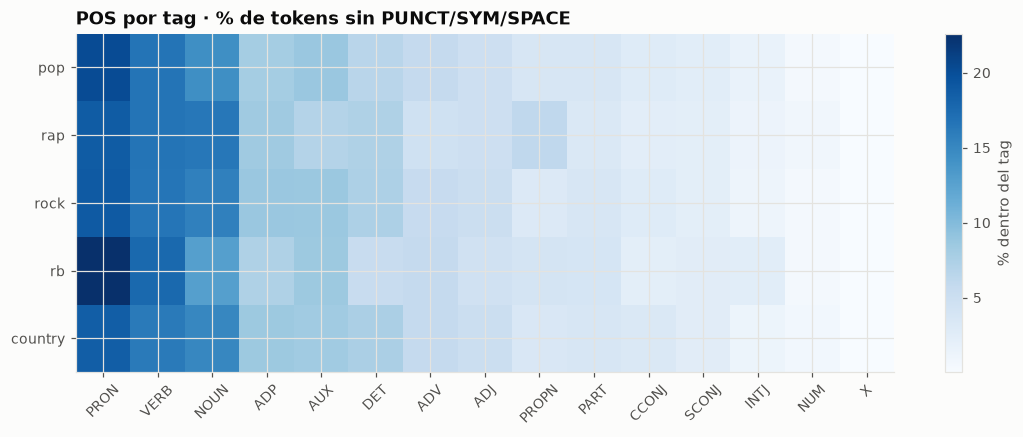

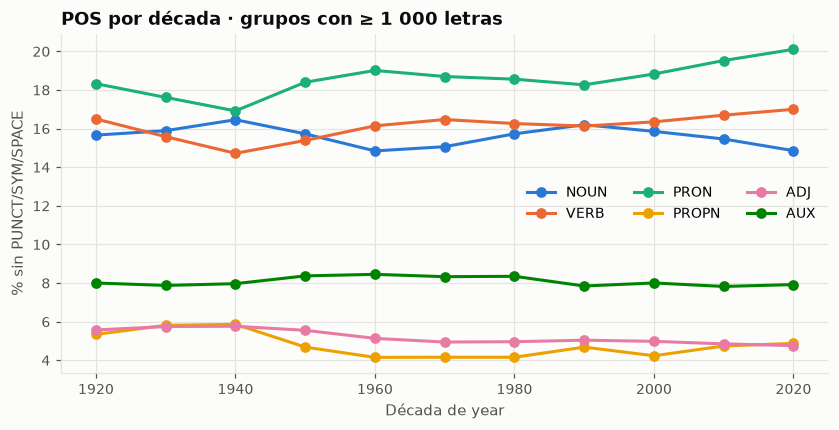

| POS | mínimo tag | mínimo % | máximo tag | máximo % | diferencia pp |
|---|---|---|---|---|---|
| PRON | country | 18.594 | rb | 22.614 | 4.020 |
| NOUN | rb | 12.761 | rap | 16.432 | 3.672 |
| PROPN | rock | 3.055 | rap | 6.046 | 2.991 |
| DET | rb | 5.357 | country | 7.606 | 2.250 |
| AUX | rap | 6.997 | pop | 8.713 | 1.716 |
| VERB | country | 16.123 | rb | 17.614 | 1.491 |
| ADP | rb | 7.299 | rock | 8.683 | 1.384 |
| INTJ | rock | 1.142 | rb | 2.426 | 1.283 |
| ADV | rap | 4.583 | country | 5.742 | 1.158 |
| CCONJ | rb | 2.254 | country | 3.341 | 1.087 |
| ADJ | rb | 4.481 | country | 5.110 | 0.629 |
| PART | rap | 3.305 | rb | 3.842 | 0.537 |
| SCONJ | rock | 2.239 | country | 2.585 | 0.346 |
| NUM | rock | 0.500 | rap | 0.787 | 0.287 |
| X | country | 0.028 | pop | 0.064 | 0.037 |

| tag | década | tokens sin puntuación | NOUN | VERB | PRON | PROPN |
|---|---|---|---|---|---|---|
| pop | 1970 | 7018973 | 15.114 | 16.400 | 18.651 | 4.072 |
| pop | 2020 | 63051314 | 13.151 | 17.034 | 21.433 | 3.777 |
| rap | 1970 | 129247 | 16.429 | 15.821 | 16.911 | 6.696 |
| rap | 2020 | 129586892 | 15.874 | 16.976 | 19.348 | 5.904 |
| rock | 1970 | 3671025 | 15.667 | 16.285 | 18.123 | 4.416 |
| rock | 2020 | 24106678 | 15.225 | 16.805 | 19.303 | 2.938 |
| rb | 1970 | 1786536 | 13.652 | 17.497 | 20.304 | 4.302 |
| rb | 2020 | 15112765 | 12.651 | 17.621 | 22.723 | 4.123 |
| country | 1970 | 1350430 | 14.923 | 16.073 | 18.578 | 3.503 |
| country | 2020 | 3849147 | 15.084 | 16.096 | 18.641 | 3.492 |

In [3]:
doc_tags = Counter(docs['tag'].to_pylist())
doc_dec = Counter(decade_of(y) for y in docs['year'].to_pylist())
tag_pos = distributions(groups, 'tag')
dec_pos = distributions(groups, 'decade')
for name, counts, rows in [('tag',doc_tags,tag_pos), ('década',doc_dec,dec_pos)]:
    sizes = []
    for g in sorted(counts, key=lambda x: str(x)):
        selected = [r for r in rows if r['group']==g]
        total = sum(r['count'] for r in selected)
        nonpunct = sum(r['count'] for r in selected if r['upos'] not in EXCLUDED)
        sizes.append({'grupo':g, 'letras':counts[g], '% letras':100*counts[g]/docs.num_rows,
                      'tokens':total, 'tokens sin puntuación/símbolos':nonpunct})
    print(name); show(sizes)
    assert sum(r['tokens'] for r in sizes) == N
    assert sum(counts.values()) == docs.num_rows
show(tag_pos); show(dec_pos)
pos_order = [r['upos'] for r in global_pos if r['upos'] not in EXCLUDED]
tags = [t for t in viz.TAG_ORDER if t in doc_tags]
matrix = np.array([[next((r['pct_nonpunct'] for r in tag_pos if r['group']==t and r['upos']==p),0)
                    for p in pos_order] for t in tags])
fig, ax = plt.subplots(figsize=(12,4))
im = ax.imshow(matrix, cmap='Blues', aspect='auto')
ax.set_xticks(range(len(pos_order)),pos_order,rotation=45); ax.set_yticks(range(len(tags)),tags)
ax.set_title('POS por tag · % de tokens sin PUNCT/SYM/SPACE')
fig.colorbar(im, ax=ax, label='% dentro del tag')
viz.save(fig, FIG/'pos_tags.png'); plt.show()
decades = sorted(d for d in doc_dec if d is not None and doc_dec[d]>=1000)
fig, ax = plt.subplots(figsize=(9,4))
for p in ['NOUN','VERB','PRON','PROPN','ADJ','AUX']:
    ax.plot(decades,[next((r['pct_nonpunct'] for r in dec_pos if r['group']==d and r['upos']==p),0)
                    for d in decades], marker='o', label=p)
ax.set(title='POS por década · grupos con ≥ 1 000 letras', xlabel='Década de year', ylabel='% sin PUNCT/SYM/SPACE')
ax.legend(ncol=3); viz.save(fig, FIG/'pos_decadas.png'); plt.show()
spread = []
for p in pos_order:
    rows = [r for r in tag_pos if r['upos']==p]
    lo, hi = min(rows,key=lambda r:r['pct_nonpunct']),max(rows,key=lambda r:r['pct_nonpunct'])
    spread.append({'POS':p,'mínimo tag':lo['group'],'mínimo %':lo['pct_nonpunct'],
                   'máximo tag':hi['group'],'máximo %':hi['pct_nonpunct'],
                   'diferencia pp':hi['pct_nonpunct']-lo['pct_nonpunct']})
show(sorted(spread,key=lambda r:-r['diferencia pp']))
# Temporal comparison within tag: separates some composition effects, not all confounding.
eligible = [d for d in decades if d >= 1970]
endpoints = [eligible[0],eligible[-1]]
within = []
for tag in tags:
    for dec in endpoints:
        sub = [r for r in groups if r['tag']==tag and r['decade']==dec]
        rr = distributions(sub)
        within.append({'tag':tag,'década':dec,'tokens sin puntuación':sum(r['count'] for r in rr if r['upos'] not in EXCLUDED),
                       **{p:next((r['pct_nonpunct'] for r in rr if r['upos']==p),0) for p in ['NOUN','VERB','PRON','PROPN']}})
show(within)

## 3. Lematización: reducción y ambigüedad (E3-01)

Se compara forma en minúsculas con lema en minúsculas para evitar contar `i → I`
como cambio morfológico. Se excluyen las mismas tres categorías UPOS.
Los tipos son cadenas únicas, no parejas `(forma, POS)`. El cociente de tipos no es
una medida de exactitud: la polisemia, el slang y errores también cambian los lemas.
Un lema puede coincidir con formas superficiales de otras palabras.

In [4]:
lemmas, merged = lemma_summary(words)
show([{k:v for k,v in lemmas.items() if k!='top_changes'}])
show(lemmas['top_changes'])
lemma_by_pos = []
for p in pos_order:
    t = merged.filter(pc.equal(merged['upos'],p))
    n = int(pc.sum(t['count']).as_py() or 0)
    changed = t.filter(pc.not_equal(t['lower'],pc.utf8_lower(t['lemma'])))
    nc = int(pc.sum(changed['count']).as_py() or 0)
    lemma_by_pos.append({'POS':p,'tokens':n,'tokens con cambio':nc,'% con cambio':100*nc/n if n else 0})
show(lemma_by_pos)
assert sum(r['tokens'] for r in lemma_by_pos)==lemmas['tokens']
assert sum(r['tokens con cambio'] for r in lemma_by_pos)==lemmas['changed_tokens']
targets = ["n't","'s","ca","wo","gon","na","ridin'","riding","runnin'","yeah","oh","yo","love"]
ambiguous = merged.filter(pc.is_in(merged['lower'],value_set=pa.array(targets)))
show(ambiguous.sort_by([('count','descending')]).slice(0,70).to_pylist())
vocables = set(yaml.safe_load((ROOT/'config/vocables.yaml').read_text(encoding='utf-8'))['vocables'])
vt = merged.filter(pc.is_in(merged['lower'],value_set=pa.array(sorted(vocables))))
vpos = vt.group_by('upos').aggregate([('count','sum')]).sort_by([('count_sum','descending')])
print('Tokens spaCy cuya forma coincide con la lista de vocablos (no todos son usos vocalizados):')
show(vpos.to_pylist())

| tokens | changed_tokens | changed_pct | surface_types | lemma_types | reduction_pct |
|---|---|---|---|---|---|
| 954321127 | 177278975 | 18.576 | 1503152 | 1450635 | 3.494 |

| lower | lemma | count_sum |
|---|---|---|
| me | I | 13916368 |
| n't | not | 13851892 |
| 'm | be | 10292562 |
| 's | be | 8875219 |
| is | be | 6351972 |
| got | get | 5003509 |
| 're | be | 3545661 |
| 'll | will | 3129954 |
| was | be | 2952572 |
| ca | can | 2593846 |
| are | be | 2503011 |
| ai | be | 2419291 |
| 've | have | 2110293 |
| been | be | 1678193 |
| them | they | 1338494 |
| gon | go | 1232561 |
| na | to | 1232561 |
| had | have | 1126739 |
| did | do | 1116989 |
| wo | will | 1096843 |
| said | say | 1078440 |
| us | we | 1077574 |
| am | be | 1072943 |
| ta | to | 1018931 |
| better | well | 908316 |

| POS | tokens | tokens con cambio | % con cambio |
|---|---|---|---|
| PRON | 185818230 | 19490448 | 10.489 |
| VERB | 159154194 | 60524364 | 38.029 |
| NOUN | 146979569 | 27720354 | 18.860 |
| ADP | 78510983 | 69104 | 0.088 |
| AUX | 75380981 | 49871883 | 66.160 |
| DET | 66877498 | 4 | 0.000 |
| ADV | 49459463 | 748536 | 1.513 |
| ADJ | 46440536 | 2422137 | 5.216 |
| PROPN | 44732914 | 177427 | 0.397 |
| PART | 33419929 | 16238650 | 48.590 |
| CCONJ | 24602151 | 2 | 0.000 |
| SCONJ | 22359077 | 4 | 0.000 |
| INTJ | 13809402 | 14876 | 0.108 |
| NUM | 6233893 | 901 | 0.014 |
| X | 542307 | 285 | 0.053 |

| lower | lemma | upos | count |
|---|---|---|---|
| n't | not | PART | 13851891 |
| 's | be | AUX | 8000051 |
| yeah | yeah | INTJ | 3709950 |
| oh | oh | INTJ | 3136546 |
| ca | can | AUX | 2593846 |
| love | love | NOUN | 2292243 |
| 's | 's | PART | 1801149 |
| love | love | VERB | 1421842 |
| na | to | PART | 1208904 |
| wo | will | AUX | 1096843 |
| gon | go | VERB | 1078496 |
| 's | be | VERB | 875168 |
| 's | us | PRON | 541729 |
| gon | gon | VERB | 411399 |
| yo | yo | PROPN | 277506 |
| yo | Yo | PROPN | 180675 |
| yeah | Yeah | PROPN | 171740 |
| love | Love | PROPN | 141894 |
| na | na | PART | 137084 |
| yo | yo | NOUN | 109350 |
| na | na | VERB | 97114 |
| gon | gon | NOUN | 93450 |
| runnin' | run | VERB | 86728 |
| riding | rid | VERB | 82216 |
| 's | 's | AUX | 81349 |
| gon | go | PROPN | 81226 |
| gon | go | NOUN | 70874 |
| gon | gon | AUX | 62108 |
| yeah | yeah | PROPN | 59551 |
| oh | oh | NOUN | 50506 |
| na | na | ADP | 46229 |
| na | na | NOUN | 44901 |
| na | Na | PROPN | 44746 |
| ridin' | rid | VERB | 38126 |
| oh | Oh | PROPN | 28745 |
| 's | ' | VERB | 24756 |
| yo | yo | INTJ | 24015 |
| na | na | AUX | 23854 |
| na | to | ADP | 22129 |
| na | na | INTJ | 19973 |
| oh | oh | PROPN | 19236 |
| riding | riding | NOUN | 16656 |
| gon | Gon | PROPN | 11912 |
| oh | oh | ADJ | 11712 |
| yeah | yeah | NOUN | 11588 |
| yo | yo | VERB | 10376 |
| oh | OH | PROPN | 8394 |
| ridin' | riding | NOUN | 8044 |
| yo | yo | ADP | 7784 |
| gon | gon | PROPN | 7261 |
| 's | 's | NOUN | 6298 |
| yo | yo | X | 4650 |
| 's | ' | NOUN | 4408 |
| yeah | yeah | NUM | 4252 |
| yeah | yeah | ADJ | 4077 |
| love | love | PROPN | 3507 |
| yo | YO | PROPN | 3213 |
| 's | us | PART | 2977 |
| yo | yo | PRON | 2951 |
| riding | Riding | PROPN | 2906 |
| na | na | PROPN | 2906 |
| 's | 's | PRON | 2824 |
| runnin' | running | NOUN | 2569 |
| yeah | YEAH | PROPN | 2226 |
| love | LOVE | PROPN | 2100 |
| na | NA | PROPN | 1896 |
| gon | go | ADJ | 1889 |
| ridin' | Riding | PROPN | 1840 |
| love | love | AUX | 1633 |
| na | to | AUX | 1527 |

Tokens spaCy cuya forma coincide con la lista de vocablos (no todos son usos vocalizados):


| upos | count_sum |
|---|---|
| INTJ | 9779177 |
| PROPN | 3793380 |
| AUX | 2421753 |
| PART | 2322631 |
| VERB | 1427262 |
| NOUN | 828569 |
| ADJ | 331644 |
| X | 142350 |
| ADP | 138712 |
| ADV | 23940 |
| PRON | 12145 |
| NUM | 6558 |
| DET | 4786 |
| CCONJ | 1738 |
| SCONJ | 1530 |

## 4. Auditoría cualitativa trazable (E3-04)

Selección **dirigida, no aleatoria ni representativa**: primer archivo de anotación
(hasta 500 letras) de cada uno de los diez shards. Se conserva el primer ejemplo por
criterio, hasta diez, con contexto de oración y posiciones originales. No se
vuelven a etiquetar los ejemplos. Los conteos de esta selección no se extrapolan.
Los textos son fragmentos breves del corpus local; los IDs y archivo permiten recuperar
la letra. `line_i`, `sent_i` y `tok_i` empiezan en cero.

In [5]:
criteria = {
 'negación contraída': lambda r:r['lower']=="n't",
 'posesivo/auxiliar ambiguo': lambda r:r['lower']=="'s",
 'slang gonna': lambda r:r['lower']=='gon',
 'g-dropping normalizado': lambda r:r['gdrop_normalized'],
 'ridin': lambda r:r['lower'].startswith('ridin'),
 'vocablo PROPN': lambda r:r['lower'] in {'oh','yeah','ooh','la','na'} and r['upos']=='PROPN',
 'interjección': lambda r:r['upos']=='INTJ',
 'nombre propio': lambda r:r['upos']=='PROPN' and r['lower'] not in vocables,
 'fragmento sin verbo': lambda r:False,
}
examples = {}; sample_docs = set(); inspected_parts=[]
for shard in sorted((NLP/'spacy_sm_v1/tokens').iterdir()):
    part = sorted(shard.glob('part-*.parquet'))[0]
    inspected_parts.append(str(part.relative_to(ROOT)))
    table = pq.read_table(part)
    sample_docs.update(table['lyrics_id'].to_pylist())
    rows = table.to_pylist()
    # First matching token per criterion, deterministic file and row order.
    for r in rows:
        for criterion, predicate in criteria.items():
            if criterion not in examples and predicate(r):
                sentence = [x for x in rows if x['lyrics_id']==r['lyrics_id'] and x['sent_i']==r['sent_i']]
                examples[criterion] = dict(criterion=criterion, file=str(part.relative_to(ROOT)),
                    lyrics_id=r['lyrics_id'],sent_i=r['sent_i'],line_i=r['line_i'],tok_i=r['tok_i'],
                    text=r['text'],upos=r['upos'],lemma=r['lemma'],gdrop=r['gdrop_normalized'],
                    context=' '.join(x['text'] for x in sentence)[:220],
                    annotation=[{k:x[k] for k in ['tok_i','text','upos','lemma']} for x in sentence[:30]])
    if 'fragmento sin verbo' not in examples:
        sentences = {}
        for r in rows: sentences.setdefault((r['lyrics_id'],r['sent_i']),[]).append(r)
        for (lid, si), sent in sentences.items():
            if 2 <= len(sent) <= 6 and not any(r['upos'] in {'VERB','AUX'} for r in sent):
                r=sent[0]
                examples['fragmento sin verbo']=dict(criterion='fragmento sin verbo',file=str(part.relative_to(ROOT)),
                    lyrics_id=lid,sent_i=si,line_i=r['line_i'],tok_i=r['tok_i'],text=r['text'],upos=r['upos'],
                    lemma=r['lemma'],gdrop=r['gdrop_normalized'],context=' '.join(x['text'] for x in sent),
                    annotation=[{k:x[k] for k in ['tok_i','text','upos','lemma']} for x in sent])
                break
    del table, rows
print('Selección:',len(sample_docs),'letras en',len(inspected_parts),'partes; criterios encontrados:',len(examples))
for criterion, ex in examples.items():
    print('\n',criterion, '|',ex['lyrics_id'],'| línea',ex['line_i'],'| oración',ex['sent_i'])
    print(ex['context']); print('Archivo:',ex['file'])
    show(ex['annotation'])
missing = sorted(set(criteria)-set(examples))
print('Criterios no encontrados en la selección:',missing)
summary = dict(version='e3-morphology-v1', docs=docs.num_rows,tokens=N,global_pos=global_pos,
               lemma=lemmas, tag_spread=spread, sample_docs=len(sample_docs),sample_parts=inspected_parts,
               examples=list(examples.values()),missing_criteria=missing)
OUT = ROOT/'reports/nlp/lyrics_full_v1'
OUT.mkdir(parents=True,exist_ok=True)
tmp = OUT/'e3_summary.json.tmp'
tmp.write_text(json.dumps(summary,ensure_ascii=False,indent=2),encoding='utf-8')
tmp.replace(OUT/'e3_summary.json')

Selección: 5000 letras en 10 partes; criterios encontrados: 9

 slang gonna | lyr_94b5237c6f7464b6c4b5 | línea 0 | oración 0
" Look , I was gon na go easy on you not to hurt your feelings "
Archivo: data\processed\nlp\lyrics_full_v1\spacy_sm_v1\tokens\train-00000-of-00010\part-00000.parquet


| tok_i | text | upos | lemma |
|---|---|---|---|
| 0 | " | PUNCT | " |
| 1 | Look | VERB | look |
| 2 | , | PUNCT | , |
| 3 | I | PRON | I |
| 4 | was | AUX | be |
| 5 | gon | VERB | go |
| 6 | na | PART | to |
| 7 | go | VERB | go |
| 8 | easy | ADV | easy |
| 9 | on | ADP | on |
| 10 | you | PRON | you |
| 11 | not | PART | not |
| 12 | to | PART | to |
| 13 | hurt | VERB | hurt |
| 14 | your | PRON | your |
| 15 | feelings | NOUN | feeling |
| 16 | " | PUNCT | " |


 posesivo/auxiliar ambiguo | lyr_94b5237c6f7464b6c4b5 | línea 2 | oración 3
" Something 's wrong , I can feel it " ( Six minutes , Slim Shady , you 're on ! )
Archivo: data\processed\nlp\lyrics_full_v1\spacy_sm_v1\tokens\train-00000-of-00010\part-00000.parquet


| tok_i | text | upos | lemma |
|---|---|---|---|
| 39 | " | PUNCT | " |
| 40 | Something | PRON | something |
| 41 | 's | PART | 's |
| 42 | wrong | NOUN | wrong |
| 43 | , | PUNCT | , |
| 44 | I | PRON | I |
| 45 | can | AUX | can |
| 46 | feel | VERB | feel |
| 47 | it | PRON | it |
| 48 | " | PUNCT | " |
| 49 | ( | PUNCT | ( |
| 50 | Six | NUM | six |
| 51 | minutes | NOUN | minute |
| 52 | , | PUNCT | , |
| 53 | Slim | PROPN | Slim |
| 54 | Shady | PROPN | Shady |
| 55 | , | PUNCT | , |
| 56 | you | PRON | you |
| 57 | 're | AUX | be |
| 58 | on | ADP | on |
| 59 | ! | PUNCT | ! |
| 60 | ) | PUNCT | ) |


 nombre propio | lyr_94b5237c6f7464b6c4b5 | línea 2 | oración 3
" Something 's wrong , I can feel it " ( Six minutes , Slim Shady , you 're on ! )
Archivo: data\processed\nlp\lyrics_full_v1\spacy_sm_v1\tokens\train-00000-of-00010\part-00000.parquet


| tok_i | text | upos | lemma |
|---|---|---|---|
| 39 | " | PUNCT | " |
| 40 | Something | PRON | something |
| 41 | 's | PART | 's |
| 42 | wrong | NOUN | wrong |
| 43 | , | PUNCT | , |
| 44 | I | PRON | I |
| 45 | can | AUX | can |
| 46 | feel | VERB | feel |
| 47 | it | PRON | it |
| 48 | " | PUNCT | " |
| 49 | ( | PUNCT | ( |
| 50 | Six | NUM | six |
| 51 | minutes | NOUN | minute |
| 52 | , | PUNCT | , |
| 53 | Slim | PROPN | Slim |
| 54 | Shady | PROPN | Shady |
| 55 | , | PUNCT | , |
| 56 | you | PRON | you |
| 57 | 're | AUX | be |
| 58 | on | ADP | on |
| 59 | ! | PUNCT | ! |
| 60 | ) | PUNCT | ) |

... (10 outputs left out)


 fragmento sin verbo | lyr_94b5237c6f7464b6c4b5 | línea 44 | oración 43
Simply rage and youthful exuberance
Archivo: data\processed\nlp\lyrics_full_v1\spacy_sm_v1\tokens\train-00000-of-00010\part-00000.parquet


| tok_i | text | upos | lemma |
|---|---|---|---|
| 535 | Simply | ADV | simply |
| 536 | rage | NOUN | rage |
| 537 | and | CCONJ | and |
| 538 | youthful | ADJ | youthful |
| 539 | exuberance | NOUN | exuberance |

Criterios no encontrados en la selección: []


WindowsPath('B:/University/2027-1/SONORA/reports/nlp/lyrics_full_v1/e3_summary.json')

## 5. Lectura lingüística y límites

- `PRON` permite examinar interlocución y persona; `VERB/AUX` acciones y modalidad;
  `NOUN/PROPN` referencias nominales. Estas categorías no determinan por sí solas temas,
  emociones ni calidad de una recomendación. Las diferencias máximas entre tags se
  cuantifican en puntos porcentuales arriba, con tamaños y denominadores explícitos.
- Las contracciones separan clíticos: `n't` puede lematizarse como `not`; `ca` es
  una pieza de `can't`, no necesariamente una palabra autónoma defectuosa. `'s` requiere
  contexto para distinguir posesivo de auxiliar. `gon`/`na` pueden proceder de `gonna`;
  por eso no debe interpretarse cada `na` como una sílaba de estribillo.
- El texto sombra reduce diferencias ortográficas de g-dropping sin garantizar un lema
  correcto. Las predicciones de `ridin` y otros ejemplos deben leerse junto al contexto:
  normalización gráfica y desambiguación morfológica son tareas distintas.
- Un vocablo repetido etiquetado `PROPN` puede reflejar desajuste de dominio del modelo;
  un nombre propio verdadero también puede repetir letras. La tabla de formas ambiguas
  y los contextos permiten discutir casos, sin reclasificar automáticamente todos los tokens.
- Los fragmentos sin verbo son compatibles con letras, títulos y respuestas breves;
  no prueban por sí solos un error. Tampoco una oración por verso equivale necesariamente
  a una oración gramatical completa. E4 profundizará en dependencias.
- La reducción de tipos por lematización y su frecuencia por POS describen compresión,
  no precisión. No existe aquí un conjunto de referencia humana: **no se estima accuracy**.
  La selección dirigida sirve para encontrar mecanismos de error, no su prevalencia.
- Los porcentajes temporales están afectados por metadatos ausentes, tamaños desiguales
  y composición por tag/artista. La comparación temporal dentro de cada tag es una
  comprobación descriptiva adicional; no elimina todos esos factores.

**Reproducibilidad:** ejecutar `build_e3.py` desde el venv del proyecto. Se usan los
agregados completos de `e2_frequency.py pos-lexicon` y la anotación ya terminada;
no se modifica `data/raw`, no se reentrena spaCy. Figuras en `reports/figures/E3/`;
resumen y procedencia de ejemplos en `reports/nlp/lyrics_full_v1/e3_summary.json`.